In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../datasets/FuelConsumptionCo2.csv');
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   object 
 2   MODEL                     1067 non-null   object 
 3   VEHICLECLASS              1067 non-null   object 
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   object 
 7   FUELTYPE                  1067 non-null   object 
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 108.5+ KB


In [5]:
df['FUELTYPE'].unique()

array(['Z', 'D', 'X', 'E'], dtype=object)

In [6]:
df['FUELTYPE'] = df['FUELTYPE'].replace({'Z':'Gasoline', 'D':'Diesel', 'E':'Ethanol', 'X':'Electricity'})
df['NUMERICFUELTYPE'] = df['FUELTYPE'].replace({'Gasoline':0, 'Diesel':1, 'Ethanol':2, 'Electricity':3})   
df.head()

/tmp/ipykernel_7168/3007155630.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['NUMERICFUELTYPE'] = df['FUELTYPE'].replace({'Gasoline':0, 'Diesel':1, 'Ethanol':2, 'Electricity':3})


,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS,NUMERICFUELTYPE
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Gasoline,9.9,6.7,8.5,33,196,0
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Gasoline,11.2,7.7,9.6,29,221,0
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Gasoline,6.0,5.8,5.9,48,136,0
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Gasoline,12.7,9.1,11.1,25,255,0
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Gasoline,12.1,8.7,10.6,27,244,0


# Feature Engineering

In [7]:
df['FUELCLASSIFICATION'] = (
    df[['FUELCONSUMPTION_COMB', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY']]
      .mean(axis=1)
      .apply(lambda x: 'baixo' if x > 12 else 'medio' if 7 < x <= 12 else 'alto')
)
df['FUELCLASSIFICATION']

0       medio
1       medio
2        alto
3       medio
4       medio
        ...  
1062    medio
1063    medio
1064    medio
1065    medio
1066    baixo
Name: FUELCLASSIFICATION, Length: 1067, dtype: object

# EDA (Exploratory Data Analisis)

In [17]:
df.describe().round(2)

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS,NUMERICFUELTYPE
count,1067.0,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00
mean,2014.0,3.35,5.79,13.30,9.47,11.58,26.44,256.23,1.64
std,0.0,1.42,1.80,4.10,2.79,3.49,7.47,63.37,1.42
min,2014.0,1.00,3.00,4.60,4.90,4.70,11.00,108.00,0.00
25%,2014.0,2.00,4.00,10.25,7.50,9.00,21.00,207.00,0.00
50%,2014.0,3.40,6.00,12.60,8.80,10.90,26.00,251.00,2.00
75%,2014.0,4.30,8.00,15.55,10.85,13.35,31.00,294.00,3.00
max,2014.0,8.40,12.00,30.20,20.50,25.80,60.00,488.00,3.00


Text(0.5, 1.0, 'Distribuição da feature CO2EMISSIONS')

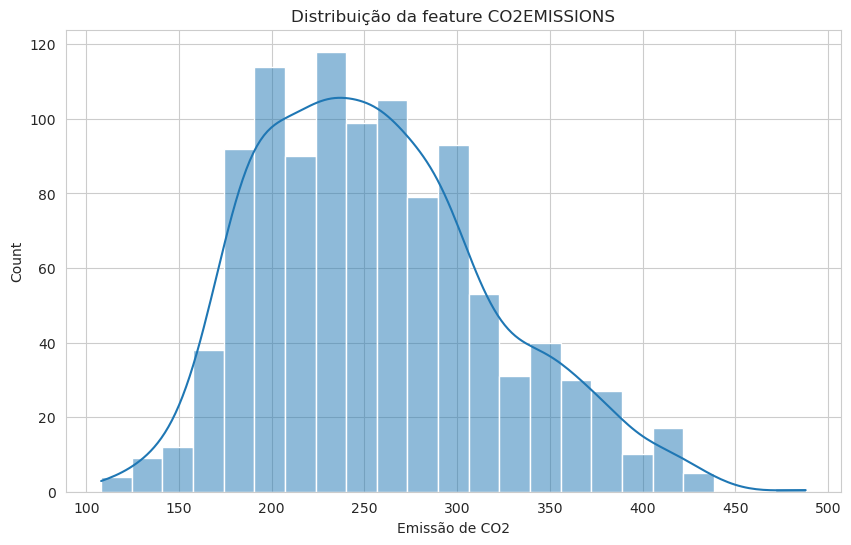

In [15]:
sns.set_style(style='whitegrid');
fig, ax = plt.subplots(figsize=(10, 6));
sns.histplot(x=df['CO2EMISSIONS'], kde=True);
ax.set_xlabel('Emissão de CO2')
plt.title('Distribuição da feature CO2EMISSIONS')

Text(0.5, 1.0, 'Boxplot de relação entre o tipo do combustível e a emissão de CO²')

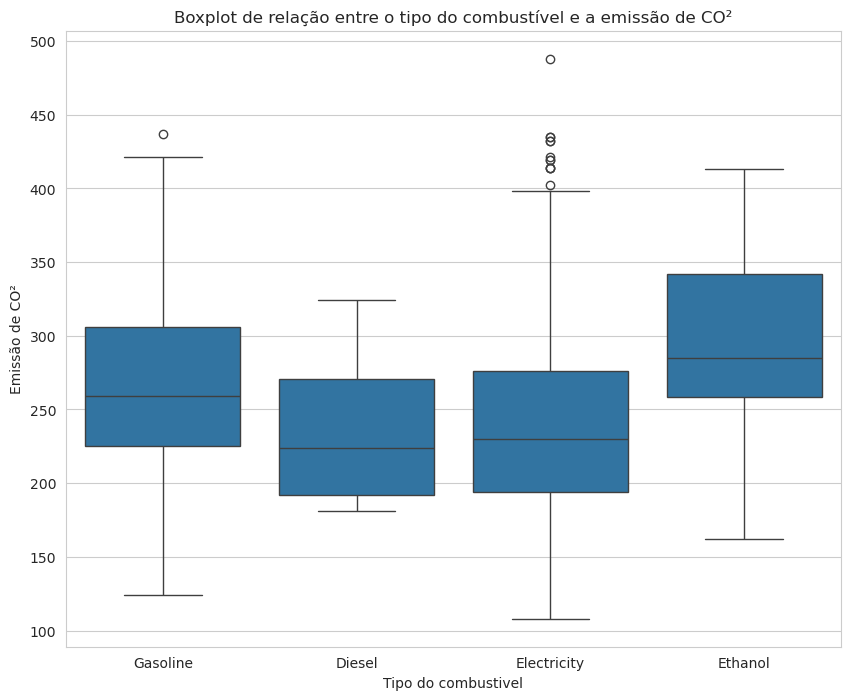

In [24]:
sns.set_style(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(x=df['FUELTYPE'], y=df['CO2EMISSIONS']);
ax.set_xlabel('Tipo do combustivel')
ax.set_ylabel('Emissão de CO²')
plt.title('Boxplot de relação entre o tipo do combustível e a emissão de CO²')

Text(0.5, 1.0, 'Mapa de calor com a correlação das variaveis')

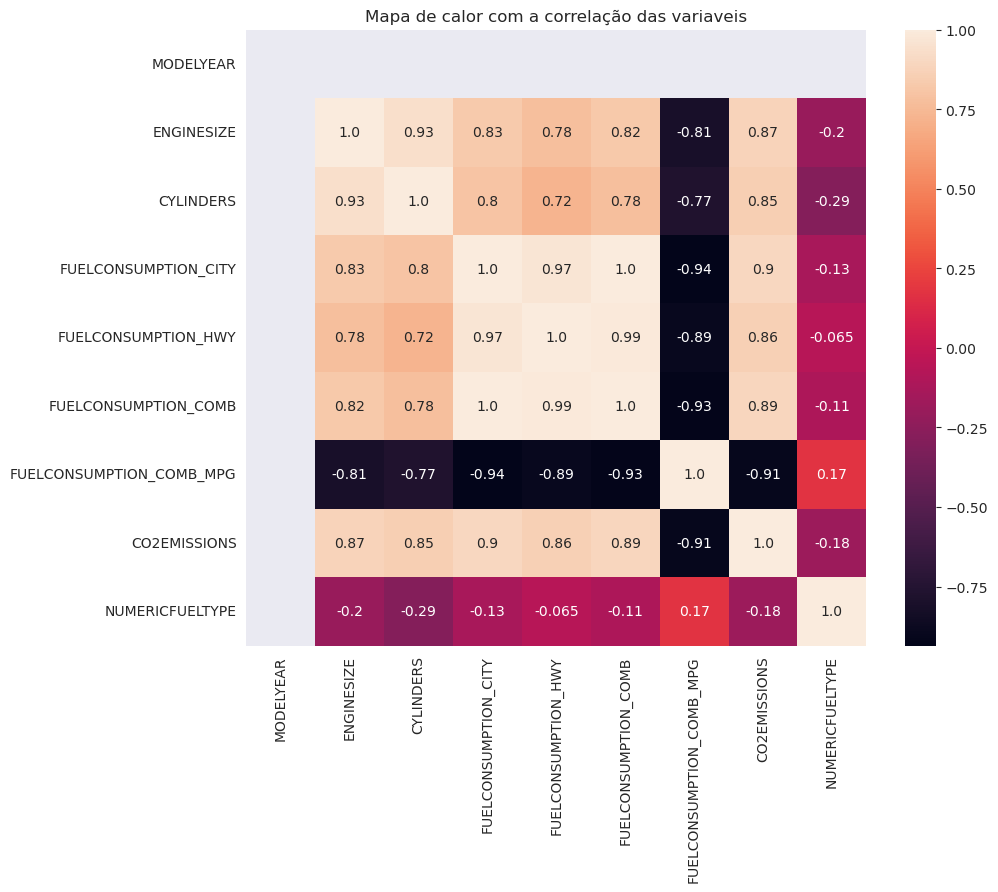

In [37]:
fig, ax = plt.subplots(figsize=(10,8))
dados_numericos = df.select_dtypes(include='number')
sns.heatmap(dados_numericos.corr(), annot=True, fmt='.2');
plt.title('Mapa de calor com a correlação das variaveis')

## Regressão Linear

Text(0.5, 1.0, 'Relação do tamanho do motor e a emissão de CO²')

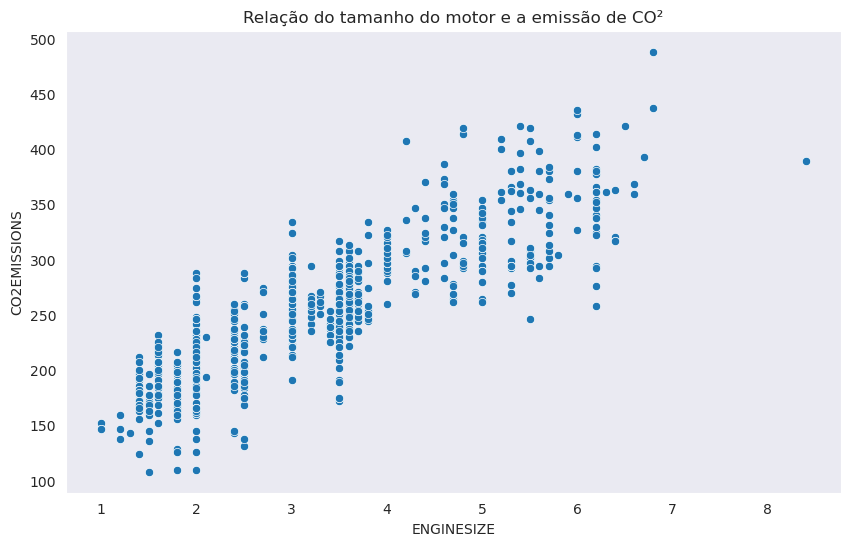

In [39]:
fig, ax = plt.subplots(figsize=(10,6))
sns.scatterplot(x=df['ENGINESIZE'], y=df['CO2EMISSIONS']);
plt.title('Relação do tamanho do motor e a emissão de CO²')

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   object 
 2   MODEL                     1067 non-null   object 
 3   VEHICLECLASS              1067 non-null   object 
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   object 
 7   FUELTYPE                  1067 non-null   object 
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
 13  NUMERICFUELTYPE           1067 non-null   int64  
 14  FUELCLAS

In [58]:
from sklearn.linear_model import LinearRegression;
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
x = df[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB']]
y = df['CO2EMISSIONS']
model = LinearRegression()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model.fit(x_train, y_train);
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred);
mae = mean_absolute_error(y_test, y_pred);
r2 = r2_score(y_test, y_pred);
print(f'Erro medio {np.sqrt(mse).round(2)}')
print(f'Erro absoluto {mae:.2f}')
print(f'Acuracia do modelo {r2 * 100:.2f}')

Erro medio 22.61
Erro absoluto 16.69
Acuracia do modelo 87.63


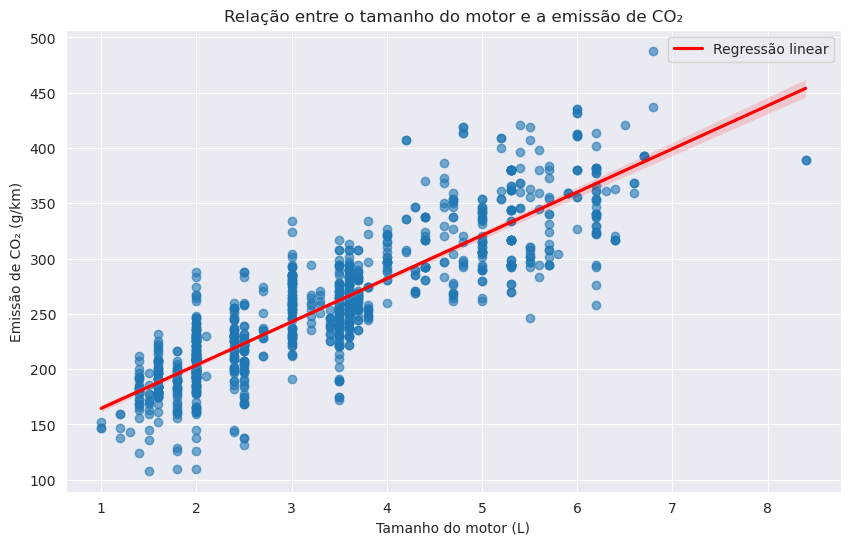

In [63]:
sns.set_style(style='darkgrid')
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(
    data=df,
    x='ENGINESIZE',
    y='CO2EMISSIONS',
    ax=ax,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red', 'label': 'Regressão linear'}
)
ax.set_title('Relação entre o tamanho do motor e a emissão de CO₂')
ax.set_xlabel('Tamanho do motor (L)')
ax.set_ylabel('Emissão de CO₂ (g/km)')
ax.legend()